# DSCI 552 - Homework 8
**Timmala Karan** | GitHub: karantimmala | USC ID: 1373267232


In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
import warnings
from threadpoolctl import threadpool_limits
thread_limits = threadpool_limits(limits=1)
warnings.filterwarnings('ignore', message='KMeans is known to have a memory leak on Windows with MKL.*', category=UserWarning)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, zero_one_loss)
from sklearn.cluster import KMeans, SpectralClustering
from scipy.special import softmax
from joblib import Parallel, delayed
def data_file(name):
    for folder in [Path('.'), Path('data'), Path('../data'), Path('upload')]:
        if (folder / name).is_file():
            return folder / name
    raise FileNotFoundError(f'Place {name} beside the notebook or in data/.')
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUC']
C_GRID = np.logspace(-3, 3, 7)
def metrics(y_true, prediction, score):
    return np.array([accuracy_score(y_true, prediction),
                     precision_score(y_true, prediction, zero_division=0),
                     recall_score(y_true, prediction, zero_division=0),
                     f1_score(y_true, prediction, zero_division=0),
                     roc_auc_score(y_true, score)])
class ConvergedLinearSVC(LinearSVC):
    def fit(self, X, y, sample_weight=None):
        while True:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', ConvergenceWarning)
                super().fit(X, y, sample_weight=sample_weight)
            if self.n_iter_ < self.max_iter:
                return self
            if (sample_weight is None and np.all(self.coef_ == 0)
                    and np.all(self.intercept_ == 0)):
                signed_y = np.where(np.asarray(y) == self.classes_[1], 1., -1.)
                gradient = 2 * self.C * (np.asarray(X).T @ signed_y)
                if self.fit_intercept:
                    gradient = np.r_[gradient, 2*self.C*self.intercept_scaling*signed_y.sum()]
                if np.max(np.abs(gradient)) <= 1 + 1e-10:
                    return self
            if self.max_iter >= 3200000:
                raise RuntimeError('SVM did not converge; reconsider C or feature scaling.')
            self.max_iter *= 4
def tune_svm(features, labels, seed=0, c_grid=None):
    # Fit scaling separately in each CV training fold, with no test information.
    pipeline = Pipeline([('scale', StandardScaler()),
                         ('svm', ConvergedLinearSVC(penalty='l1', dual=False,
                                           max_iter=200000, tol=1e-3, random_state=seed))])
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    search = GridSearchCV(pipeline, {'svm__C': C_GRID if c_grid is None else c_grid}, cv=cv,
                          scoring='accuracy', n_jobs=1, error_score='raise')
    return search.fit(features, labels).best_estimator_
def show_averages(train_values, test_values):
    display(pd.DataFrame([np.mean(train_values, axis=0), np.mean(test_values, axis=0)],
                         index=['Train', 'Test'], columns=METRICS).round(6))
def show_run(run, title):
    fig, ax = plt.subplots(figsize=(4.2, 2.7))
    for name, (truth, prediction, score) in run.items():
        fpr, tpr, _ = roc_curve(truth, score)
        ax.plot(fpr, tpr, label=f'{name}: AUC={roc_auc_score(truth, score):.4f}')
        print(f'{name} confusion matrix (rows=true, columns=predicted; B=0, M=1):')
        print(confusion_matrix(truth, prediction, labels=[0, 1]))
    ax.plot([0, 1], [0, 1], '--', color='gray')
    ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title=title)
    ax.legend(); fig.tight_layout(); plt.show()


## 1. Learning methods: breast cancer data
### (a) Data preparation
The dataset contains 569 observations and 30 predictors. The identifier is excluded because it identifies an observation rather than describing its measured characteristics. Diagnosis is encoded as benign = 0 and malignant = 1. Thus, precision, recall and F1 in this section describe malignant detection.

The classes contain 357 benign and 212 malignant cases. Because benign cases are more frequent, accuracy alone can conceal weak malignant detection. Recall measures the fraction of malignant cases detected, while precision measures how often a malignant prediction is correct. F1 balances precision and recall. AUC evaluates score ranking across thresholds, rather than classification at one fixed threshold.


In [2]:
df = pd.read_csv(data_file('wdbc.data'), header=None)
X = df.iloc[:, 2:].astype(float).to_numpy()  # Exclude ID and diagnosis.
y = df.iloc[:, 1].map({'B': 0, 'M': 1}).to_numpy()
print('Samples and predictors:', X.shape)


Samples and predictors: (569, 30)


In [3]:
print('Class distribution (B=0, M=1):')
print(pd.Series(y).value_counts().sort_index())


Class distribution (B=0, M=1):
0    357
1    212
Name: count, dtype: int64


### (b)(i) Supervised L1 SVM
The experiment uses 30 seeded, stratified 80/20 splits. Each split contains 455 training observations and 114 test observations, including 72 benign and 42 malignant cases. The same split seeds are reused across the four methods, allowing comparisons on the same held-out cases within each repetition.

Five-fold accuracy cross-validation selects C from seven logarithmic values between 0.001 and 1000. StandardScaler is fitted inside each CV training fold, preventing validation information from entering the feature scaling. The selected pipeline is refitted on the full training split before training and test metrics are calculated. The L1 penalty can set some coefficients to zero, although this experiment evaluates predictive performance rather than reporting a selected-feature analysis.


In [4]:
M = 30
results_summary = {}
train_metrics, test_metrics = [], []
for i in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=i)
    model = tune_svm(X_train, y_train, i)
    train_result = (y_train, model.predict(X_train), model.decision_function(X_train))
    test_result = (y_test, model.predict(X_test), model.decision_function(X_test))
    train_metrics.append(metrics(*train_result)); test_metrics.append(metrics(*test_result))
    if i == 0:
        supervised_run = {'Train': train_result, 'Test': test_result}
show_averages(train_metrics, test_metrics)


,Accuracy,Precision,Recall,F1-score,AUC
Train,0.986813,0.991423,0.973137,0.982177,0.997349
Test,0.967251,0.973734,0.937302,0.954594,0.993056


Train confusion matrix (rows=true, columns=predicted; B=0, M=1):
[[284   1]
 [  3 167]]
Test confusion matrix (rows=true, columns=predicted; B=0, M=1):
[[69  3]
 [ 2 40]]


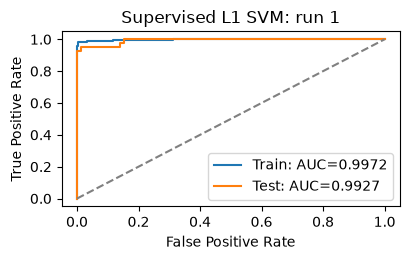

In [5]:
show_run(supervised_run, 'Supervised L1 SVM: run 1')


**Supervised results:** Mean training accuracy is 98.68%, while mean test accuracy is 96.73%, a gap of about 1.96 percentage points. Test precision of 0.9737 means most malignant predictions are correct; recall of 0.9373 shows that some malignant cases are still missed. Test F1 is 0.9546 and AUC is 0.9931, supporting strong classification and score ranking across the repeated splits.

In the displayed run, the training matrix contains 284 true benign cases, one false positive, three false negatives and 167 true malignant cases. The test matrix contains 69 true benign cases, three false positives, two false negatives and 40 true malignant cases. Thus the displayed test accuracy is 109/114 = 95.61%. This is one selected run, so it need not equal the 96.73% average over all 30 runs. The ROC figure likewise describes that run rather than an average ROC.


In [6]:
results_summary['Supervised'] = {'Train': np.mean(train_metrics, axis=0),
                                 'Test': np.mean(test_metrics, axis=0)}


### (b)(ii) Self-training L1 SVM
Randomly label half of each training class, rounded down. Tune C on those cases, then repeatedly pseudo-label the farthest remaining point and refit.


In [7]:
train_metrics, test_metrics = [], []
for i in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=i)
    rng = np.random.default_rng(i)
    labeled = np.concatenate([rng.choice(np.flatnonzero(y_train == label),
                            size=np.sum(y_train == label)//2, replace=False)
                            for label in [0, 1]])
    unlabeled = np.setdiff1d(np.arange(len(y_train)), labeled)
    initial_model = tune_svm(X_train[labeled], y_train[labeled], i)
    scaler = initial_model.named_steps['scale']
    model = initial_model.named_steps['svm']
    train_scaled, test_scaled = scaler.transform(X_train), scaler.transform(X_test)
    features, labels = train_scaled[labeled].copy(), y_train[labeled].copy()
    # Keep the initially tuned C and scaler fixed while adding pseudo-labels.
    while len(unlabeled):
        position = np.argmax(np.abs(model.decision_function(train_scaled[unlabeled])))
        selected = unlabeled[position]
        pseudo_label = model.predict(train_scaled[selected:selected+1])
        features = np.vstack([features, train_scaled[selected]])
        labels = np.concatenate([labels, pseudo_label])
        unlabeled = np.delete(unlabeled, position)
        model.fit(features, labels)
    train_result = (y_train, model.predict(train_scaled), model.decision_function(train_scaled))
    test_result = (y_test, model.predict(test_scaled), model.decision_function(test_scaled))
    train_metrics.append(metrics(*train_result)); test_metrics.append(metrics(*test_result))
    if i == 0:
        semi_run = {'Train': train_result, 'Test': test_result}
show_averages(train_metrics, test_metrics)


,Accuracy,Precision,Recall,F1-score,AUC
Train,0.978535,0.982435,0.960000,0.970948,0.994895
Test,0.960819,0.962759,0.930952,0.945798,0.992262


Train confusion matrix (rows=true, columns=predicted; B=0, M=1):
[[284   1]
 [  5 165]]
Test confusion matrix (rows=true, columns=predicted; B=0, M=1):
[[69  3]
 [ 2 40]]


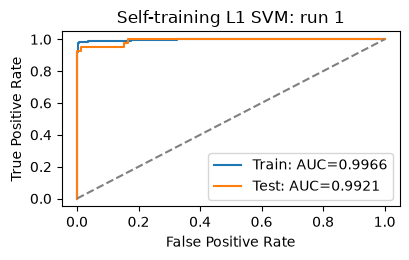

In [8]:
show_run(semi_run, 'Self-training L1 SVM: run 1')


The self-training model starts with half of each training class labeled, rounded down when a class count is odd. C is selected using only those labeled examples. The initial scaler and selected C remain fixed as pseudo-labeled cases are added, so the procedure does not retune the penalty using hidden true labels.

Mean training accuracy is 97.85%, compared with mean test accuracy of 96.08%. Test precision is 0.9628, recall is 0.9310 and F1 is 0.9458. These results show that the classifier identifies most malignant cases while maintaining relatively few false malignant predictions. Test AUC is 0.9923, indicating strong ranking despite the limited initial label budget.

In the illustrated run, the test confusion matrix has 69 true benign predictions, three false positives, two missed malignant cases and 40 detected malignant cases. It happens to match the supervised model's test confusion matrix in that run. This does not make the methods identical: their averages differ across the 30 splits. Self-training can reinforce an incorrect early pseudo-label, so adding every unlabeled case does not guarantee an improvement over the starting model.


In [9]:
results_summary["Semi-Supervised"] = {
    "Train": np.mean(train_metrics, axis=0),
    "Test": np.mean(test_metrics, axis=0)
}


### (b)(iii) K-means, k = 2
**A. Initialization:** K-means minimizes within-cluster squared distances and can settle at different local minima from different starting centers. Each fit uses 50 random starts and retains the solution with the smallest inertia. Run-specific seeds make these starts reproducible.

Multiple starts reduce the risk of retaining an unnecessarily poor solution, but do not prove that the global minimum has been reached. Increasing the number of iterations alone is also not a guarantee of a better minimum: it mainly allows an individual initialization to converge. Predictors are standardized using training data so large-scale measurements do not dominate Euclidean distance solely because of their units.


**B. Training:** Form two clusters without diagnosis labels. For each center, identify its 30 closest training members and use their majority diagnosis to name the entire cluster. These labels name an already formed cluster; they do not guide the K-means fitting objective.

All five metrics are averaged over 30 splits. Although cluster formation is unsupervised, the subsequent mapping to benign or malignant uses labeled training examples, as required by the assignment. Therefore, these results describe K-means used as a classifier with a labeled naming step, rather than a completely label-free diagnosis system.


In [10]:
train_metrics, test_metrics = [], []
for i in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=i)
    scaler = StandardScaler()
    train_scaled, test_scaled = scaler.fit_transform(X_train), scaler.transform(X_test)
    kmeans = KMeans(n_clusters=2, init='random', n_init=50, random_state=i).fit(train_scaled)
    cluster_labels = np.zeros(2, dtype=int)
    for cluster in range(2):
        members = np.flatnonzero(kmeans.labels_ == cluster)
        distances = np.linalg.norm(train_scaled[members] - kmeans.cluster_centers_[cluster], axis=1)
        nearest = members[np.argsort(distances)[:30]]
        cluster_labels[cluster] = int(y_train[nearest].mean() > 0.5)
    def kmeans_result(features, truth):
        distances = kmeans.transform(features)
        prediction = cluster_labels[np.argmin(distances, axis=1)]
        weights = softmax(-distances, axis=1)
        score = weights[:, cluster_labels == 1].sum(axis=1)
        return truth, prediction, score
    train_result = kmeans_result(train_scaled, y_train)
    test_result = kmeans_result(test_scaled, y_test)
    train_metrics.append(metrics(*train_result)); test_metrics.append(metrics(*test_result))
    if i == 0:
        kmeans_run = {'Train': train_result, 'Test': test_result}
print('K-means averages over 30 runs:')
show_averages(train_metrics, test_metrics)


K-means averages over 30 runs:


,Accuracy,Precision,Recall,F1-score,AUC
Train,0.910183,0.923846,0.828235,0.873242,0.974864
Test,0.905263,0.909638,0.826190,0.864657,0.971869


Train confusion matrix (rows=true, columns=predicted; B=0, M=1):
[[277   8]
 [ 33 137]]


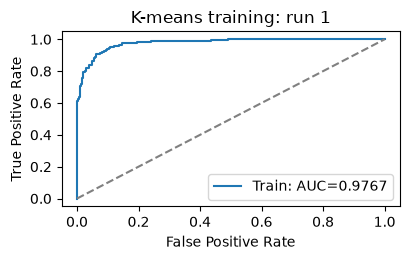

In [11]:
show_run({'Train': kmeans_run['Train']}, 'K-means training: run 1')


**K-means training results:** Mean training accuracy is 91.02%, recall is 0.8282 and F1 is 0.8732. In run 1, the matrix has 277 correctly identified benign cases and 137 correctly identified malignant cases, with eight false positives and 33 false negatives. The larger false-negative count indicates that the cluster labeling misses more malignant cases than it incorrectly flags benign cases.

Mean training AUC is 0.9749, substantially higher than the fixed-rule F1. This is not contradictory: the continuous proximity score can rank many cases well even when the nearest-center decision and majority labels do not produce the best possible class boundary.


**C. Testing:** Assign each test observation to the nearest fitted training center and retain the training-derived cluster label. Test diagnoses are not used to rename clusters. For ROC/AUC, softmax(-distance) assigns greater weight to nearer centers; weights belonging to malignant-labeled clusters are added to obtain a malignant score. These relative proximity scores are not calibrated disease probabilities.


Test confusion matrix (rows=true, columns=predicted; B=0, M=1):
[[65  7]
 [ 7 35]]


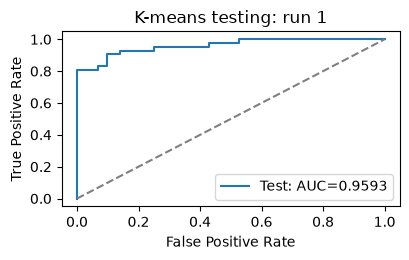

In [12]:
show_run({'Test': kmeans_run['Test']}, 'K-means testing: run 1')


**K-means test results:** Mean test accuracy is 90.53%, precision is 0.9096, recall is 0.8262 and F1 is 0.8647. Training and test accuracy are close, suggesting that the weaker performance relative to the SVMs is not explained by a large training-to-test accuracy gap alone.

The illustrated test matrix has 65 true benign predictions, seven false positives, seven false negatives and 35 true malignant predictions. Its accuracy is 100/114 = 87.72%, which is below the 30-run mean. The mean test AUC of 0.9719 reflects the score ranking across thresholds, while this matrix reflects one split and one classification rule.


In [13]:
results_summary['Unsupervised'] = {'Train': np.mean(train_metrics, axis=0),
                                   'Test': np.mean(test_metrics, axis=0)}


### (b)(iv) Spectral clustering
Spectral clustering represents observations as a similarity graph. Here, an RBF kernel with gamma = 1 assigns larger affinities to nearby observations. Eigenvectors of a graph Laplacian supply an embedding in which groups are assigned. This construction can capture non-convex groups for which a single original-space center is an inadequate description.

The implementation uses fit_predict and does not assign spectral labels by distance to original-space centers. Gamma is kept at the value explicitly allowed by the assignment. The results therefore evaluate one fixed gamma and preprocessing combination; no search over alternative spectral settings is claimed.


,Accuracy,Precision,Recall,F1-score,AUC
Train,0.629451,0.866667,0.008235,0.016302,0.504352
Test,0.634795,0.366667,0.008730,0.017054,0.504365


Training-only cluster sizes in run 1: [453   2]
Train confusion matrix (rows=true, columns=predicted; B=0, M=1):
[[285   0]
 [168   2]]


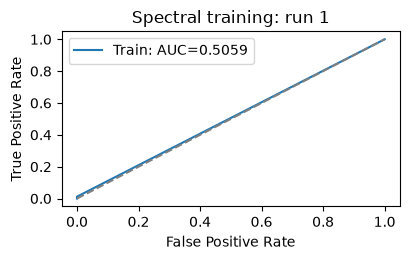

In [14]:
def spectral_result(train_features, train_labels, evaluation_features, seed):
    combined = np.vstack([train_features, evaluation_features])
    clusters = SpectralClustering(n_clusters=2, affinity='rbf', gamma=1,
                                 assign_labels='kmeans', n_init=50,
                                 random_state=seed).fit_predict(combined)
    training_clusters = clusters[:len(train_labels)]
    fractions = np.array([train_labels[training_clusters == k].mean()
                          if np.any(training_clusters == k) else train_labels.mean()
                          for k in [0, 1]])
    score = fractions[clusters]
    return (score > 0.5).astype(int), score, np.bincount(clusters, minlength=2)
train_metrics, test_metrics = [], []
spectral_sizes = []
for i in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=i)
    scaler = StandardScaler()
    train_scaled, test_scaled = scaler.fit_transform(X_train), scaler.transform(X_test)
    prediction, score, sizes = spectral_result(train_scaled, y_train, train_scaled[:0], i)
    train_result = (y_train, prediction, score)
    train_metrics.append(metrics(*train_result))
    # Transductive test evaluation: include test features, never test labels, in the graph.
    prediction, score, _ = spectral_result(train_scaled, y_train, test_scaled, i)
    test_result = (y_test, prediction[len(y_train):], score[len(y_train):])
    test_metrics.append(metrics(*test_result))
    spectral_sizes.append(sizes)
    if i == 0:
        spectral_run = {'Train': train_result, 'Test': test_result}
show_averages(train_metrics, test_metrics)
print('Training-only cluster sizes in run 1:', spectral_sizes[0])
show_run({'Train': spectral_run['Train']}, 'Spectral training: run 1')


Cluster classes are determined from the malignant fraction among their training members. A fraction above 0.5 gives the malignant prediction, and the fraction itself supplies the ROC score. A cluster containing no training observations uses the overall training malignant fraction. Test diagnoses are never consulted for this mapping.

Only two cluster-level scores are available, so the ROC has few operating points. This is expected for the voting-based score and should not be interpreted as a smoothly calibrated probability model. AUC still summarizes the ranking induced by those scores.

The training-only graph in run 1 produces clusters of 453 and two observations. Its confusion matrix correctly identifies all 285 benign cases but detects only two of 170 malignant cases, missing 168. Across runs, mean malignant recall is only 0.0082 and mean F1 is 0.0163. Although mean precision is 0.8667, that precision accompanies extremely few malignant predictions and does not demonstrate useful malignant detection.


Test confusion matrix (rows=true, columns=predicted; B=0, M=1):
[[72  0]
 [42  0]]


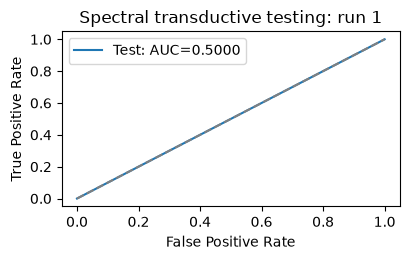

In [15]:
show_run({'Test': spectral_run['Test']}, 'Spectral transductive testing: run 1')


**Test protocol:** SpectralClustering has no ordinary predict method for unseen observations. For the test experiment, fit_predict is applied to combined training and test features, with feature scaling learned on training data only. Class mappings and malignant fractions are computed exclusively from the training portion of the resulting clusters.

This is a transductive, batch-dependent evaluation: the graph changes with the supplied test features. Training metrics use a separate training-only graph. Consequently, the spectral test results do not represent exactly the same inductive prediction task as the SVM and nearest-center K-means results. Including test features in the graph is an explicitly stated protocol choice, while test labels remain reserved for evaluation.

In the illustrated test run, every observation is predicted benign: 72 benign cases are correct and all 42 malignant cases are missed. Across 30 runs, test accuracy averages 63.48%, recall is 0.0087, F1 is 0.0171 and AUC is 0.5044. The test split's benign-only accuracy is 72/114 = 63.16%, so the reported accuracy is only slightly above that baseline. This supports the conclusion that the fixed spectral setting provides little useful malignant discrimination.


In [16]:
results_summary['Spectral Clustering'] = {'Train': np.mean(train_metrics, axis=0),
                                          'Test': np.mean(test_metrics, axis=0)}


### (b)(v) Method comparison


In [17]:
summary_rows = []
for method, values in results_summary.items():
    for split in ['Train', 'Test']:
        summary_rows.append({'Method': method, 'Split': split,
                             **dict(zip(METRICS, values[split]))})
results_df = pd.DataFrame(summary_rows)
display(results_df.round(6))


,Method,Split,Accuracy,Precision,Recall,F1-score,AUC
0,Supervised,Train,0.986813,0.991423,0.973137,0.982177,0.997349
1,Supervised,Test,0.967251,0.973734,0.937302,0.954594,0.993056
2,Semi-Supervised,Train,0.978535,0.982435,0.960000,0.970948,0.994895
3,Semi-Supervised,Test,0.960819,0.962759,0.930952,0.945798,0.992262
4,Unsupervised,Train,0.910183,0.923846,0.828235,0.873242,0.974864
5,Unsupervised,Test,0.905263,0.909638,0.826190,0.864657,0.971869
6,Spectral Clustering,Train,0.629451,0.866667,0.008235,0.016302,0.504352
7,Spectral Clustering,Test,0.634795,0.366667,0.008730,0.017054,0.504365


The supervised SVM has the highest mean test accuracy, 96.73%, followed by self-training at 96.08% and K-means at 90.53%. The supervised advantage over self-training is approximately 0.64 percentage points. The result is consistent with the benefit of having all training labels, but these averages alone do not show that the difference is statistically significant.

The SVMs also have the strongest malignant-detection results. Supervised test precision, recall and F1 are 0.9737, 0.9373 and 0.9546; the corresponding self-training values are 0.9628, 0.9310 and 0.9458. Self-training retains much of the fully supervised performance with only half of each class initially labeled, while still allowing errors from pseudo-label propagation.

K-means has test AUC 0.9719, but recall 0.8262 and F1 0.8647 are lower at its chosen classification rule. A high AUC describes a useful ordering of cases across possible thresholds; it does not guarantee equally strong predictions at one operating point. Its cluster geometry is also optimized for compactness, rather than separation of the diagnosis classes.

Spectral clustering performs worst in this experiment. Its accuracy of 63.48% must be considered together with recall of 0.0087 and AUC of 0.5044. The extreme imbalance of its clusters explains why accuracy can look moderate while malignant detection is almost absent. This conclusion is limited to gamma = 1 with the chosen scaling and stated transductive evaluation.

Training accuracy exceeds test accuracy for the SVMs and K-means, but the reported gaps are modest. Neither this comparison nor the ranking above is a significance test. The methods also use labels differently: the SVMs learn a boundary from labels, whereas the clustering methods use training labels to name groups after cluster formation.


## 2. Active learning with SVMs
### (a) Banknote data
The banknote dataset has four numerical predictors and a binary class response. A fixed stratified split supplies 900 training cases and 472 test cases. Test cases are reserved for evaluation and are never added to an acquisition pool.

Each acquisition repetition begins from the same initial pool for its passive and active learners. This pairing makes the early comparison more informative than comparing methods that started with unrelated labeled examples. The 50 repetitions vary acquisition randomness on one fixed train/test split; they do not average performance over 50 different holdout splits.


In [18]:
banknotes = pd.read_csv(data_file('data_banknote_authentication.txt'), header=None)
X_bank, y_bank = banknotes.iloc[:, :-1].to_numpy(), banknotes.iloc[:, -1].astype(int).to_numpy()
X_train_bank, X_test_bank, y_train_bank, y_test_bank = train_test_split(
    X_bank, y_bank, test_size=472, stratify=y_bank, random_state=0)
print('Training samples:', len(y_train_bank), 'Test samples:', len(y_test_bank))


Training samples: 900 Test samples: 472


### (b)(i) Passive learning
Repeat the acquisition procedure 50 times. Begin with 10 random training cases and add 10 randomly ordered unused cases after each fitted model. At pool sizes 10, 20, ..., 900, select C using five-fold CV, fit an L1 linear SVM and record the held-out test error.

The growing pool retains previously acquired labels and samples without replacement. Each repetition therefore produces 90 test errors, giving an error array of shape (50, 90). The 900-point endpoint uses all training observations. Passive selection does not depend on the current model's uncertainty, making it the random-acquisition baseline.


In [19]:
n_runs, step_size = 50, 10
BANKNOTE_C_GRID = np.logspace(-3, 1, 9)
training_sizes = np.arange(10, 901, step_size)
def initial_pool(labels, seed):
    rng = np.random.default_rng(seed)
    while True:
        chosen = rng.choice(len(labels), size=10, replace=False)
        if np.bincount(labels[chosen], minlength=2).min() >= 2:
            return chosen, rng
def learning_run(run, active):
    selected, rng = initial_pool(y_train_bank, run)
    remaining = np.setdiff1d(np.arange(900), selected)
    if not active:
        remaining = rng.permutation(remaining)
    errors = []
    for size in training_sizes:
        pool_y = y_train_bank[selected]
        import warnings
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='The least populated class in y has only')
            model = tune_svm(X_train_bank[selected], pool_y, run, c_grid=BANKNOTE_C_GRID)
        errors.append(zero_one_loss(y_test_bank, model.predict(X_test_bank)))
        if len(remaining):
            positions = (np.argsort(np.abs(model.decision_function(X_train_bank[remaining])))[:10]
                         if active else np.arange(10))
            selected = np.concatenate([selected, remaining[positions]])
            remaining = np.delete(remaining, positions)
    assert len(selected) == len(np.unique(selected)) == 900
    return np.array(errors)
passive_errors = np.array(Parallel(n_jobs=4)(delayed(learning_run)(run, False) for run in range(n_runs)))
passive_avg_errors = passive_errors.mean(axis=0)
print('Passive errors shape:', passive_errors.shape)


Passive errors shape: (50, 90)


### (b)(ii) Active learning
Use the same fixed split and opening pool as passive learning. After fitting the current SVM, rank remaining training observations by absolute decision score and acquire the 10 nearest the hyperplane. Obtain their true labels, append them to the labeled pool and remove them from the reserve.

For a fixed fitted hyperplane, dividing decision scores by the weight-vector norm would not change their order. Absolute decision scores therefore implement the required distance ranking. These near-boundary examples are uncertain for the current classifier, although uncertainty alone does not guarantee that every acquired batch will improve test performance.

Active learning differs from self-training: active acquisition obtains the selected cases' true labels, whereas self-training assigns the model's own predictions. No point is acquired twice. The saved active error array also has shape (50, 90), allowing errors to be averaged at matching label budgets.


In [20]:
active_errors = np.array(Parallel(n_jobs=4)(delayed(learning_run)(run, True) for run in range(n_runs)))
active_avg_errors = active_errors.mean(axis=0)
print('Active errors shape:', active_errors.shape)


Active errors shape: (50, 90)


**Settings and numerical checks:** Initial ten-point draws are resampled until each class has at least two members. This is a stated feasibility restriction that keeps both classes in every five-fold CV training subset; it does not force a five/five class balance. Some validation folds may contain one class, which is compatible with the accuracy scoring used here.

At each pool size, C is reselected over nine logarithmic values from 0.001 to 10. Scaling is fitted within CV using the current labeled pool, then refitted on that pool for the final selected model. Neither test labels nor reserve labels enter penalty selection. Reserve labels become available to the active learner only when their cases are acquired.

Difficult fits retry with larger iteration limits. An iteration-limited zero solution is accepted only after its L1 optimality condition is checked; other unresolved fits raise an error. The warning controls limit the repeated Windows/MKL warning output without globally hiding unrelated warnings. These numerical checks do not change the acquisition rule.


### (c) Mean learning curves
For each of the 90 label budgets, average its test errors across the 50 repetitions. The figure compares these pointwise means, and the table highlights selected budgets. Lower test error at the same budget indicates better predictive performance for the same number of acquired labels.

The average of the first 20 plotted means summarizes budgets 10-200. It weights those budgets equally and is not a separate model's error estimate or a statistical significance test.


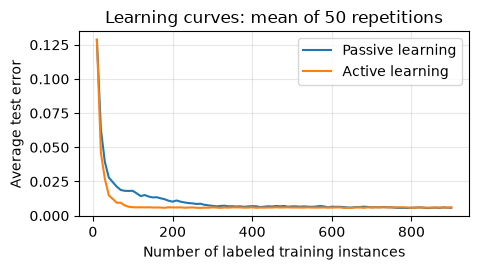

Selected mean errors:


,Training Size,Passive Avg Error,Active Avg Error
0,10,0.128686,0.128686
4,50,0.024492,0.012161
9,100,0.018178,0.006144
19,200,0.010254,0.006059
89,900,0.005763,0.006102


Mean test error over pool sizes 10-200: passive 0.02552118644067796 active 0.016400423728813545
Pool sizes where active has lower mean error: 74 of 90


In [21]:
passive_avg_errors, active_avg_errors = passive_errors.mean(axis=0), active_errors.mean(axis=0)
results_table = pd.DataFrame({'Training Size': training_sizes,
                              'Passive Avg Error': passive_avg_errors,
                              'Active Avg Error': active_avg_errors})
fig, ax = plt.subplots(figsize=(4.8, 2.8))
ax.plot(training_sizes, passive_avg_errors, label='Passive learning')
ax.plot(training_sizes, active_avg_errors, label='Active learning')
ax.set(xlabel='Number of labeled training instances', ylabel='Average test error',
       title='Learning curves: mean of 50 repetitions')
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()
print('Selected mean errors:')
display(results_table[results_table['Training Size'].isin([10, 50, 100, 200, 900])].round(6))
print('Mean test error over pool sizes 10-200: passive', passive_avg_errors[:20].mean(),
      'active', active_avg_errors[:20].mean())
print('Pool sizes where active has lower mean error:', int(np.sum(active_avg_errors < passive_avg_errors)), 'of 90')


Both methods start at the same mean error, approximately 12.87%, because their opening pool and fitting configuration are paired. As more labels become available, their errors generally decrease, but individual steps need not improve monotonically.

At 50 labels, passive mean error is 2.45% and active mean error is 1.22%. At 100 labels, the values are 1.82% and 0.61%; the absolute reduction is about 1.20 percentage points. At 200 labels, passive error is 1.03% and active error is 0.61%. These selected budgets show that active acquisition reaches low error with fewer labels in the early part of this experiment.

Across budgets 10-200, the mean of the plotted errors is 2.55% passive versus 1.64% active. Active error is lower at 74 of the 90 budgets, so the observed advantage is frequent but not universal. The graph also shows that the gap narrows as both methods gain access to more of the training set.

At 900 labels, passive error is 0.576% and active error is 0.610%. Both methods then use the same training cases; the acquisition order can change membership of the shuffled CV folds, the selected C and numerical fits. This small endpoint difference should not be interpreted as evidence that selecting fewer labels helped passive learning.

The main practical result is improved early label efficiency for active learning on this split. It is not a guarantee of lower error at every budget or on another dataset. The curve summarizes 50 paired acquisition repetitions on one fixed holdout split, and no confidence intervals or significance tests are reported.


## References
Homework 8 instructions; scikit-learn documentation for [LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html), [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), [SpectralClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html), and [preprocessing](https://scikit-learn.org/stable/common_pitfalls.html).
